# 01 · Setup and framing

**Project:** ICU in-hospital mortality prediction (PhysioNet/CinC Challenge 2012)

## The question
Using only data from the **first 48 hours** of an ICU stay, can we predict whether the patient **dies in hospital**, and can a model beat **SAPS-I**, the severity score clinicians already use?

## Framing
| Item | Choice | Why |
|---|---|---|
| Unit of analysis | One ICU stay (one `RecordID`) | Each record file is one stay |
| Label | `In-hospital_death` (1 = died) | Official challenge target |
| Inputs | Vitals, labs and descriptors recorded in hours 0 to 48 | Prediction is made at the 48 h mark, nothing later may be used |
| Baseline | SAPS-I score (and SOFA as a second reference) | Standard clinical severity scores, already in the outcomes file |
| Metrics | AUROC, AUPRC, calibration | AUROC: ranking. AUPRC: deaths are a minority, so precision on positives matters. Calibration: a predicted 30% should mean about 30% die |

## Leakage to watch for
`Length_of_stay` and `Survival` in the outcomes files are **future information** (known only after discharge or death). They must never become features.

## This notebook
1. Environment check
2. Check the raw files are in place
3. Load and inspect outcomes and one patient record
4. Integrity checks (counts, ID overlap between sets)
5. Outcome rate per set
6. SAPS-I and SOFA baseline AUROC / AUPRC
7. Split plan, saved to `data/processed/splits.csv`

In [1]:
# ── Cell 1: environment check and paths ─────────────────────────────
# INSIGHTS
# - Paths are built from the repo root, so the notebook works from any machine
#   as long as it lives in notebooks/.
# - RANDOM_STATE is fixed once here and reused everywhere for reproducibility.
# - Result: Python 3.14.3, numpy 2.5.5, pandas 3.1.1, scikit-learn 1.9.1, matplotlib 3.11.2
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
for p in (PROCESSED, FIGURES):
    p.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

print(f"Python       {platform.python_version()}")
print(f"numpy        {np.__version__}")
print(f"pandas       {pd.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"matplotlib   {matplotlib.__version__}")
print(f"Repo root    {ROOT}")

Python       3.14.3
numpy        2.5.5
pandas       3.1.1
scikit-learn 1.9.1
matplotlib   3.11.2
Repo root    C:\Users\user\source\icu-mortality


In [2]:
# ── Cell 2: are the raw files in place? ──────────────────────────────
# INSIGHTS
# - We need 3 record archives (set-a/b/c) and 3 outcome files.
# - Each set can be a .zip, a .tar.gz or an extracted folder. PhysioNet only
#   offers set-c as .tar.gz, so the readers handle all three formats.
# - Files are read straight from the archives by src/data_io.py, no manual unpacking needed.
# - Result: all 6 present. set-a.zip 7.9 MB, set-b.zip 8.0 MB, set-c.tar.gz 6.6 MB,
#   each Outcomes file about 79 KB.
from src.data_io import find_source

EXPECTED_OUTCOMES = [f"Outcomes-{s}.txt" for s in "abc"]

status = []
for s in "abc":
    try:
        src = find_source(RAW, s)
        size = "folder" if src.is_dir() else f"{src.stat().st_size / 1e6:.1f} MB"
        status.append({"file": src.name, "present": True, "size": size})
    except FileNotFoundError:
        status.append({"file": f"set-{s} (.zip, .tar.gz or folder)", "present": False, "size": "-"})
for name in EXPECTED_OUTCOMES:
    f = RAW / name
    status.append({"file": name, "present": f.exists(),
                   "size": f"{f.stat().st_size / 1e3:.0f} KB" if f.exists() else "-"})

status = pd.DataFrame(status)
display(status)
missing = status.loc[~status["present"], "file"].tolist()
assert not missing, f"Missing in {RAW}: {missing}. Download them from PhysioNet first."
print("All raw files found.")

,file,present,size
0,set-a.zip,True,7.9 MB
1,set-b.zip,True,8.0 MB
2,set-c.tar.gz,True,6.6 MB
3,Outcomes-a.txt,True,79 KB
4,Outcomes-b.txt,True,79 KB
5,Outcomes-c.txt,True,79 KB


All raw files found.


In [3]:
# ── Cell 3: load and inspect the outcomes files ──────────────────────
# INSIGHTS
# - Columns: RecordID, SAPS-I, SOFA, Length_of_stay, Survival, In-hospital_death.
# - -1 is the dataset's code for "missing" in SAPS-I, SOFA and Length_of_stay.
#   We convert it to NaN so it never gets treated as a real score.
# - In Survival, -1 means no death was recorded (the patient survived), so it is
#   left alone. We do not use Survival anyway.
# - Length_of_stay and Survival are post-outcome information: LEAKAGE, never features.
# - Result: 4,000 rows per set (12,000 total). All columns int64, so -1 codes are numbers, not NaN.
#   Missing (-1) codes: SAPS-I 518 (4.3%), SOFA 403 (3.4%), Length_of_stay 167.
#   Survival -1 for 7,410 stays (no recorded death).
from src.data_io import SETS, read_outcomes, list_records, read_record

outcomes = pd.concat([read_outcomes(RAW, s) for s in SETS], ignore_index=True)
print("Shape:", outcomes.shape)
print("\nDtypes:\n", outcomes.dtypes, sep="")

MISSING_CODE = -1
code_counts = (outcomes[["SAPS-I", "SOFA", "Length_of_stay", "Survival"]] == MISSING_CODE).sum()
print("\nCount of -1 (missing) codes per column:\n", code_counts, sep="")

for col in ["SAPS-I", "SOFA", "Length_of_stay"]:
    outcomes[col] = outcomes[col].replace(MISSING_CODE, np.nan)

display(outcomes.head())
display(outcomes.groupby("set").size().rename("rows").to_frame())

Shape: (12000, 7)

Dtypes:
RecordID             int64
SAPS-I               int64
SOFA                 int64
Length_of_stay       int64
Survival             int64
In-hospital_death    int64
set                    str
dtype: object

Count of -1 (missing) codes per column:
SAPS-I             518
SOFA               403
Length_of_stay     167
Survival          7410
dtype: int64


,RecordID,SAPS-I,SOFA,Length_of_stay,Survival,In-hospital_death,set
0,132539,6.0,1.0,5.0,-1,0,a
1,132540,16.0,8.0,8.0,-1,0,a
2,132541,21.0,11.0,19.0,-1,0,a
3,132543,7.0,1.0,9.0,575,0,a
4,132545,17.0,2.0,4.0,918,0,a


,rows
set,
a,4000
b,4000
c,4000


In [4]:
# ── Cell 4: what does one patient record look like? ──────────────────
# INSIGHTS
# - Long format: one row per measurement (Time, Parameter, Value).
# - Rows at Time 00:00 for RecordID, Age, Gender, Height, ICUType, Weight are
#   static descriptors, not measurements. -1 means unknown here too.
# - Each variable is measured at its own irregular times, so most hour-by-variable
#   cells are empty. That is why Phase 2 aggregates per stay (min/max/mean/last/count).
# - Result: 273 rows in set-a/132539.txt (6 descriptors + 267 measurements),
#   18 distinct parameters. Height and Weight are -1 (unknown) for this stay.
recs_a = list_records(RAW, "a")
example = read_record(RAW, "a", recs_a[0])
print(f"Example file: set-a/{recs_a[0]}  ({len(example)} rows)")
display(example.head(12))

DESCRIPTORS = ["RecordID", "Age", "Gender", "Height", "ICUType", "Weight"]
is_desc = (example["Time"] == "00:00") & example["Parameter"].isin(DESCRIPTORS)
print("\nStatic descriptors:")
display(example[is_desc].set_index("Parameter")["Value"].to_frame().T)

ts = example[~is_desc]
print(f"Time-series rows: {len(ts)}, distinct parameters: {ts['Parameter'].nunique()}")
display(ts["Parameter"].value_counts().to_frame("n_measurements"))

Example file: set-a/132539.txt  (273 rows)


,Time,Parameter,Value
0,00:00,RecordID,132539.00
1,00:00,Age,54.00
2,00:00,Gender,0.00
3,00:00,Height,-1.00
4,00:00,ICUType,4.00
5,00:00,Weight,-1.00
6,00:07,GCS,15.00
7,00:07,HR,73.00
8,00:07,NIDiasABP,65.00
9,00:07,NIMAP,92.33



Static descriptors:


Parameter,RecordID,Age,Gender,Height,ICUType,Weight
Value,132539.0,54.0,0.0,-1.0,4.0,-1.0


Time-series rows: 267, distinct parameters: 18


,n_measurements
Parameter,
RespRate,42
Urine,38
HR,37
NIDiasABP,34
NIMAP,34
NISysABP,34
Temp,14
GCS,13
HCT,3


In [5]:
# ── Cell 5: integrity checks ─────────────────────────────────────────
# INSIGHTS
# - Every record file should have exactly one outcomes row, and vice versa.
# - RecordIDs must not appear in two sets, otherwise splitting by set would leak.
# - Result: 4,000 files per set, every file has exactly one outcomes row (0 mismatches),
#   0 duplicate RecordIDs, 0 overlap between any two sets.
rows = []
ids_by_set = {}
for s in SETS:
    file_ids = {int(Path(f).stem) for f in list_records(RAW, s)}
    out_ids = set(outcomes.loc[outcomes["set"] == s, "RecordID"])
    ids_by_set[s] = out_ids
    rows.append({
        "set": s,
        "record_files": len(file_ids),
        "outcome_rows": len(out_ids),
        "files_without_outcome": len(file_ids - out_ids),
        "outcomes_without_file": len(out_ids - file_ids),
    })
display(pd.DataFrame(rows))

print("Duplicate RecordIDs inside outcomes:", outcomes["RecordID"].duplicated().sum())
for a, b in [("a", "b"), ("a", "c"), ("b", "c")]:
    print(f"Overlap set-{a} / set-{b}: {len(ids_by_set[a] & ids_by_set[b])}")

,set,record_files,outcome_rows,files_without_outcome,outcomes_without_file
0,a,4000,4000,0,0
1,b,4000,4000,0,0
2,c,4000,4000,0,0


Duplicate RecordIDs inside outcomes: 0
Overlap set-a / set-b: 0
Overlap set-a / set-c: 0
Overlap set-b / set-c: 0


In [6]:
# ── Cell 6: outcome rate per set ─────────────────────────────────────
# INSIGHTS
# - Mortality is the minority class, so accuracy is misleading (predicting
#   "survives" for everyone already scores high). This is why we use AUROC/AUPRC.
# - A random model's AUPRC equals the mortality rate, so that is the AUPRC floor.
# - Similar rates across sets mean set-c is a fair test set for a+b.
# - Result: mortality a 13.9% (554), b 14.2% (568), c 14.6% (585), overall 14.2% (1,707 of 12,000).
LABEL = "In-hospital_death"
rate = (outcomes.groupby("set")[LABEL]
        .agg(stays="size", deaths="sum", mortality_rate="mean"))
rate.loc["all"] = [len(outcomes), outcomes[LABEL].sum(), outcomes[LABEL].mean()]
rate["mortality_rate"] = rate["mortality_rate"].map("{:.1%}".format)
display(rate)

,stays,deaths,mortality_rate
set,,,
a,4000,554,13.9%
b,4000,568,14.2%
c,4000,585,14.6%
all,12000,1707,14.2%


In [7]:
# ── Cell 7: SAPS-I and SOFA baseline ─────────────────────────────────
# INSIGHTS
# - The score itself is used as a risk ranking: higher score = higher risk.
#   AUROC and AUPRC only need a ranking, so no model fitting is needed.
# - Stays with a missing score are dropped for that score's row only, and the
#   count is reported (dropping silently would flatter the baseline).
# - 95% CIs come from 1,000 bootstrap resamples, so we can tell later whether
#   a model's gain over SAPS-I is real or noise.
# - Result: SAPS-I on set-c AUROC 0.658 [0.635, 0.681], AUPRC 0.251 [0.223, 0.284] (n=3,834).
#   SOFA on set-c AUROC 0.636 [0.611, 0.661], AUPRC 0.254 [0.224, 0.288] (n=3,878).
from sklearn.metrics import roc_auc_score, average_precision_score

rng = np.random.default_rng(RANDOM_STATE)

def boot_ci(y, s, metric, n=1000):
    y, s = np.asarray(y), np.asarray(s)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        vals.append(metric(y[idx], s[idx]))
    return np.percentile(vals, [2.5, 97.5])

results = []
for score in ["SAPS-I", "SOFA"]:
    for s in list(SETS) + ["all"]:
        d = outcomes if s == "all" else outcomes[outcomes["set"] == s]
        d = d.dropna(subset=[score])
        y, sc = d[LABEL].values, d[score].values
        auroc, auprc = roc_auc_score(y, sc), average_precision_score(y, sc)
        lo_r, hi_r = boot_ci(y, sc, roc_auc_score)
        lo_p, hi_p = boot_ci(y, sc, average_precision_score)
        results.append({
            "score": score, "set": s, "n": len(d),
            "n_missing_score": int((outcomes if s == "all" else outcomes[outcomes["set"] == s])[score].isna().sum()),
            "prevalence": y.mean(),
            "AUROC": f"{auroc:.3f} [{lo_r:.3f}, {hi_r:.3f}]",
            "AUPRC": f"{auprc:.3f} [{lo_p:.3f}, {hi_p:.3f}]",
        })
baseline = pd.DataFrame(results)
baseline["prevalence"] = baseline["prevalence"].map("{:.1%}".format)
display(baseline)

,score,set,n,n_missing_score,prevalence,AUROC,AUPRC
0,SAPS-I,a,3810,190,13.9%,"0.650 [0.626, 0.675]","0.226 [0.200, 0.257]"
1,SAPS-I,b,3838,162,14.3%,"0.671 [0.648, 0.693]","0.257 [0.228, 0.292]"
2,SAPS-I,c,3834,166,14.5%,"0.658 [0.635, 0.681]","0.251 [0.223, 0.284]"
3,SAPS-I,all,11482,518,14.2%,"0.660 [0.647, 0.673]","0.244 [0.227, 0.262]"
4,SOFA,a,3856,144,14.1%,"0.623 [0.598, 0.645]","0.253 [0.222, 0.288]"
5,SOFA,b,3863,137,14.5%,"0.654 [0.630, 0.678]","0.263 [0.230, 0.299]"
6,SOFA,c,3878,122,14.6%,"0.636 [0.611, 0.661]","0.254 [0.224, 0.288]"
7,SOFA,all,11597,403,14.4%,"0.638 [0.623, 0.651]","0.255 [0.237, 0.275]"


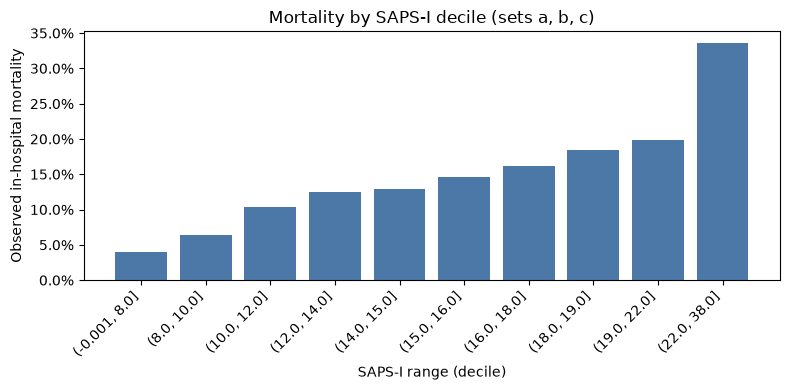

,mortality_rate,stays
saps_decile,,
"(-0.001, 8.0]",0.039844,1280
"(8.0, 10.0]",0.063792,1113
"(10.0, 12.0]",0.103704,1350
"(12.0, 14.0]",0.124759,1555
"(14.0, 15.0]",0.129717,848
"(15.0, 16.0]",0.146028,856
"(16.0, 18.0]",0.161206,1526
"(18.0, 19.0]",0.183976,674
"(19.0, 22.0]",0.199161,1431


In [8]:
# ── Cell 8: does mortality rise with SAPS-I? ─────────────────────────
# INSIGHTS
# - Groups stays into SAPS-I deciles and plots the observed death rate per decile.
# - A steady rise confirms SAPS-I ranks risk well. A raw score is not a probability,
#   so formal calibration of SAPS-I needs a mapping (e.g. logistic) fitted on a+b.
#   That comparison belongs in Phase 5.
# - Result: death rate rises steadily from 4.0% in the lowest decile (SAPS-I <= 8)
#   to 33.6% in the highest (SAPS-I 23 to 38).
d = outcomes.dropna(subset=["SAPS-I"]).copy()
d["saps_decile"] = pd.qcut(d["SAPS-I"], 10, duplicates="drop")
by_dec = d.groupby("saps_decile", observed=True)[LABEL].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(by_dec)), by_dec["mean"], color="#4C78A8")
ax.set_xticks(range(len(by_dec)))
ax.set_xticklabels([str(i) for i in by_dec.index], rotation=45, ha="right")
ax.set_xlabel("SAPS-I range (decile)")
ax.set_ylabel("Observed in-hospital mortality")
ax.set_title("Mortality by SAPS-I decile (sets a, b, c)")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
fig.savefig(FIGURES / "01_mortality_by_saps_decile.png", dpi=150)
plt.show()
display(by_dec.rename(columns={"mean": "mortality_rate", "size": "stays"}))

## Split plan

| Split | Sets | Used for |
|---|---|---|
| Development | set-a + set-b (about 8,000 stays) | Training, cross-validation, model and threshold selection |
| Test | set-c (about 4,000 stays) | Touched **once**, at the end, to report final numbers |

**Why split by set instead of a random split?**
- Each `RecordID` is one stay and lives in exactly one set (checked in Cell 5), so no stay can leak across splits.
- set-c behaves like a separate batch of patients, which is closer to how a model meets new data in practice.
- Inside development we use **stratified 5-fold cross-validation** (keeps the death rate equal across folds).

**Caveat:** the dataset does not give a patient ID separate from the stay, so if a patient had two ICU stays they could in theory land in different sets. The challenge describes records as distinct patients, so we accept this and note it under limitations.

**Rule:** anything learned from data (imputation values, scaling, feature selection) is fit on the training folds only.

In [9]:
# ── Cell 9: save the split assignment ────────────────────────────────
# INSIGHTS
# - One row per RecordID: split (dev/test) and fold (0-4 for dev, -1 for test).
# - Saved once, so every later notebook uses identical folds and results are comparable.
# - Result: dev 8,000 stays (5 folds of 1,600), test 4,000 stays. Fold death rates
#   14.0% to 14.1%, test 14.6%.
from sklearn.model_selection import StratifiedKFold

splits = outcomes[["RecordID", "set", LABEL]].copy()
splits["split"] = np.where(splits["set"] == "c", "test", "dev")
splits["fold"] = -1

dev_idx = splits.index[splits["split"] == "dev"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for k, (_, val) in enumerate(skf.split(dev_idx, splits.loc[dev_idx, LABEL])):
    splits.loc[dev_idx[val], "fold"] = k

out_path = PROCESSED / "splits.csv"
splits[["RecordID", "set", "split", "fold"]].to_csv(out_path, index=False)
print(f"Saved {out_path.relative_to(ROOT)}")

display(splits.groupby(["split", "fold"])[LABEL]
        .agg(stays="size", mortality_rate="mean")
        .style.format({"mortality_rate": "{:.1%}"}))

Saved data\processed\splits.csv


## Summary

- Stays: a 4,000, b 4,000, c 4,000 (12,000 total). Every record file matches exactly one outcomes row, with no RecordID shared between sets.
- Mortality: a 13.9%, b 14.2%, c 14.6% (14.2% overall). The rates are similar, so set-c is a fair test set.
- SAPS-I on set-c: AUROC **0.658** [0.635, 0.681], AUPRC **0.251** [0.223, 0.284] ← **the numbers to beat**
- SOFA on set-c: AUROC 0.636 [0.611, 0.661], AUPRC 0.254 [0.224, 0.288]
- Integrity: 0 mismatches, 0 duplicates, 0 cross-set overlap. SAPS-I is missing (-1) for 518 stays and SOFA for 403, and these are excluded from the baseline numbers.
- SAPS-I ranks risk sensibly: decile mortality goes from 4.0% to 33.6%. Its AUROC of about 0.66 is modest, though, which leaves room for a model.
- Splits: dev (a+b) has 5 folds of 1,600 stays at 14.0% to 14.1% mortality. Test (c) has 4,000 stays at 14.6%.

Copy the key numbers into `PROJECT_NOTES.md`.

**Next:** `02_wrangling.ipynb` turns each stay's long time series into one row of features.